# NumPy Mathematical and Statistical Functions

NumPy provides fast functions for element-wise math (**ufuncs**), summaries (**aggregations**), cumulative operations and **linear algebra**. With them, a statistical analysis or a small model needs only a few lines.

**After this lesson you can:**

1. Apply universal functions element-wise.
2. Aggregate along axes, and handle missing values with `nan` functions.
3. Compute percentiles, cumulative sums, differences and correlations.
4. Fit a linear regression with linear algebra (`@`, `np.linalg.lstsq`).

**Data:** Palmer penguins (344 penguins, 3 species, Antarctica; CC0) and Seattle weather.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])   # NOAA daily weather, Seattle

import json

penguins = pd.DataFrame(json.loads(datasets.fetch("penguins.json").read_text()))
cols = ["Beak Length (mm)", "Beak Depth (mm)", "Flipper Length (mm)", "Body Mass (g)"]
X = penguins[cols].to_numpy(dtype=float)               # (344, 4), contains NaN for missing measurements
species = penguins["Species"].to_numpy()
print(X.shape, "| missing values per column:", np.isnan(X).sum(axis=0))

(344, 4) | missing values per column: [2 2 2 2]


## 1. Universal Functions (ufuncs)

A **ufunc** works element by element on whole arrays: `np.sqrt`, `np.exp`, `np.log`, `np.abs`, `np.round`, `np.clip`, `np.maximum`, and the operators `+ - * / ** %`. They return arrays of the same shape.

In [2]:
mass_kg = X[:, 3] / 1000
print("mass in kg (first 5)       :", mass_kg[:5])
print("log of mass (first 5)      :", np.log(mass_kg[:5]).round(3))
print("beak ratio length/depth    :", (X[:5, 0] / X[:5, 1]).round(2))
temps = weather["temp_max"].to_numpy()
print("°C -> °F (first 5)         :", (temps[:5] * 9 / 5 + 32).round(1))
print("clip to [0, 30] (min, max) :", np.clip(temps, 0, 30).min(), np.clip(temps, 0, 30).max())

mass in kg (first 5)       : [3.75 3.8  3.25  nan 3.45]
log of mass (first 5)      : [1.322 1.335 1.179   nan 1.238]
beak ratio length/depth    : [2.09 2.27 2.24  nan 1.9 ]
°C -> °F (first 5)         : [55.  51.1 53.1 54.  48. ]
clip to [0, 30] (min, max) : 0.0 30.0


## 2. Aggregations and Missing Values

`sum`, `mean`, `std`, `min`, `max`, `argmin`, `argmax` reduce an array, optionally along an axis. One `NaN` makes the normal functions return `NaN`; the `nan` versions (`np.nanmean`, `np.nanstd`, ...) ignore missing values.

In [3]:
print("np.mean(X, axis=0)   :", np.mean(X, axis=0))
print("np.nanmean(X, axis=0):", np.nanmean(X, axis=0).round(1))
print("np.nanstd(X, axis=0) :", np.nanstd(X, axis=0).round(1))

complete = ~np.isnan(X).any(axis=1)                    # rows without any missing value
print(f"\ncomplete rows: {complete.sum()} of {len(X)}")
for s in np.unique(species):
    m = (species == s) & complete
    print(f"{s:<10} n={m.sum():3d}  mean mass {X[m, 3].mean():6.0f} g  heaviest {X[m, 3].max():6.0f} g")

np.mean(X, axis=0)   : [nan nan nan nan]
np.nanmean(X, axis=0): [  43.9   17.2  200.9 4201.8]
np.nanstd(X, axis=0) : [  5.5   2.   14.  800.8]

complete rows: 342 of 344
Adelie     n=151  mean mass   3701 g  heaviest   4775 g
Chinstrap  n= 68  mean mass   3733 g  heaviest   4800 g
Gentoo     n=123  mean mass   5076 g  heaviest   6300 g


## 3. Percentiles, Cumulative Operations, Correlation

In [4]:
Xc = X[complete]
q = np.percentile(Xc[:, 3], [5, 25, 50, 75, 95])
print("body mass percentiles 5/25/50/75/95:", q)

rain = weather["precipitation"].to_numpy()
cum_rain = np.cumsum(rain)                             # running total
day_to_day = np.diff(temps)                            # change from one day to the next
print(f"total rain 2012-2015: {cum_rain[-1]:.0f} mm | largest day-to-day rise: {day_to_day.max():.1f} °C, drop: {day_to_day.min():.1f} °C")

corr = np.corrcoef(Xc, rowvar=False)                   # 4 x 4 correlation matrix
print("\ncorrelation matrix:\n", corr.round(2))

body mass percentiles 5/25/50/75/95: [3150. 3550. 4050. 4750. 5650.]
total rain 2012-2015: 4426 mm | largest day-to-day rise: 9.5 °C, drop: -11.1 °C

correlation matrix:
 [[ 1.   -0.24  0.66  0.6 ]
 [-0.24  1.   -0.58 -0.47]
 [ 0.66 -0.58  1.    0.87]
 [ 0.6  -0.47  0.87  1.  ]]


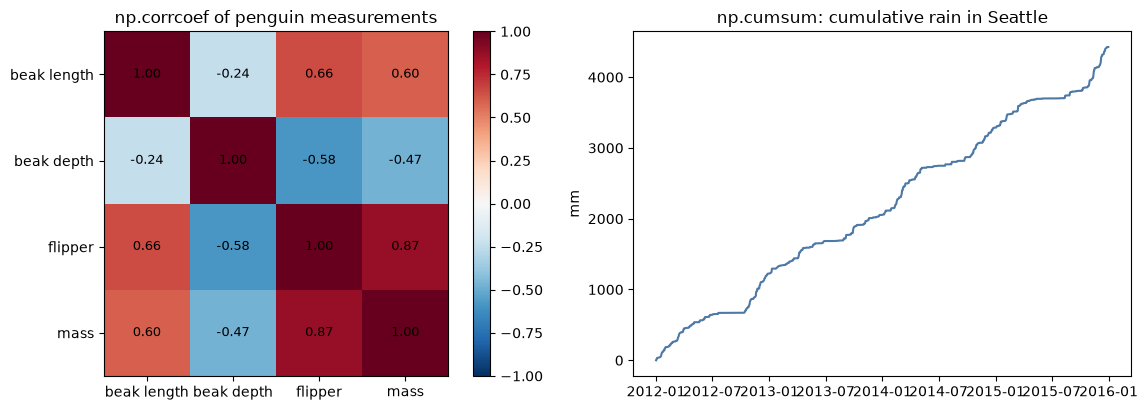

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
im = ax1.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
short = ["beak length", "beak depth", "flipper", "mass"]
ax1.set(xticks=range(4), yticks=range(4), xticklabels=short, yticklabels=short, title="np.corrcoef of penguin measurements")
for i in range(4):
    for j in range(4):
        ax1.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax1)
ax2.plot(weather["date"], cum_rain, color="#4E79A7")
ax2.set(title="np.cumsum: cumulative rain in Seattle", ylabel="mm")
plt.tight_layout()
plt.show()

Flipper length and body mass are strongly correlated. Beak depth correlates **negatively** with mass over all penguins, although within each species the relation is positive: the species differ (Simpson's paradox, see M06).

## 4. Linear Algebra: Fit a Regression

The model $\text{mass} \approx b_0 + b_1 \cdot \text{flipper}$ in matrix form is $\mathbf{y} \approx X\mathbf{b}$, with a column of ones in $X$ for the intercept. The **least-squares** solution minimises $\lVert \mathbf{y} - X\mathbf{b} \rVert^2$ and solves the normal equations $X^\top X \mathbf{b} = X^\top \mathbf{y}$. `np.linalg.lstsq` computes it in a numerically stable way.

normal equations: intercept -5780.8, slope 49.69
lstsq           : intercept -5780.8, slope 49.69  -> each extra mm of flipper adds ~50 g
R² = 0.759


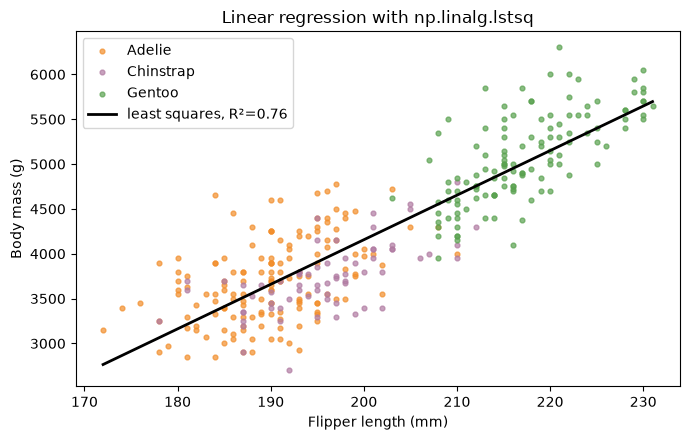

In [6]:
flipper, mass = Xc[:, 2], Xc[:, 3]
A = np.column_stack([np.ones_like(flipper), flipper])          # design matrix (n, 2)

b_normal = np.linalg.solve(A.T @ A, A.T @ mass)                # normal equations, @ = matrix product
b_lstsq, residuals, rank, _ = np.linalg.lstsq(A, mass, rcond=None)
pred = A @ b_lstsq
r2 = 1 - ((mass - pred) ** 2).sum() / ((mass - mass.mean()) ** 2).sum()
print(f"normal equations: intercept {b_normal[0]:.1f}, slope {b_normal[1]:.2f}")
print(f"lstsq           : intercept {b_lstsq[0]:.1f}, slope {b_lstsq[1]:.2f}  -> each extra mm of flipper adds ~{b_lstsq[1]:.0f} g")
print(f"R² = {r2:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for s, color in zip(np.unique(species), ["#F28E2B", "#B07AA1", "#59A14F"]):
    m = species[complete] == s
    ax.scatter(flipper[m], mass[m], s=12, alpha=0.7, color=color, label=s)
xs = np.linspace(flipper.min(), flipper.max(), 50)
ax.plot(xs, b_lstsq[0] + b_lstsq[1] * xs, color="black", lw=2, label=f"least squares, R²={r2:.2f}")
ax.set(xlabel="Flipper length (mm)", ylabel="Body mass (g)", title="Linear regression with np.linalg.lstsq")
ax.legend()
plt.tight_layout()
plt.show()

This is exactly what `LinearRegression` in scikit-learn computes (M16): libraries wrap these NumPy operations.

*Insight: Most statistics and classical machine learning reduce to a few NumPy operations: ufuncs to transform, aggregations along an axis to summarise, and `@` / `linalg` to fit models. Always decide explicitly how missing values are handled (`nan` functions or removal) before you aggregate.*

## Real-World Use Case or Analogy

Ufuncs are like a **stamp** pressed on every cell of a sheet at once; aggregations are a **calculator** run down a column; linear algebra is a **recipe** that combines many columns into one prediction.

Finance teams compute returns with `np.diff` and `np.log`, risk with `np.percentile` (value at risk), and portfolio variance with matrix products. Scientists fit calibration curves with `lstsq`. The same functions run on GPUs in CuPy and PyTorch (M38).